# Model Experiments: Kryptonite-20, -30 and -40

The paper claims that polynomial logistic regression stays below 59% up to degree 10, that more training data does not help, and that no model reaches the 90% target. Its Future Works asks which other models (neural networks, trees, clustering) would work, and what degree and how many examples a polynomial would need. This notebook tests these in order with one protocol, scores the final pipeline on a locked test set, and writes the hidden-set predictions to `hiddenlabels/` at the repository root.

The helper code is in `experiment_tools.py`; it needs `codecarbon` for the energy measurement. Finished results are also kept in `exp_cache/` (git-ignored, not needed to reproduce anything) so that an interrupted run resumes; delete that folder for a fresh run. Set the environment variable `KRYP_QUICK=1` for a dry run on 3,000 rows with small grids; its numbers mean nothing and no predictions are written.

In [1]:
import experiment_tools as et
from experiment_tools import G, NS, cv_by_fold, cv_config

print(
    "QUICK dry run" if et.QUICK else "Full run",
    f"- {et.K}-fold CV on 80% of the rows, 20% locked test",
)

Full run - 5-fold CV on 80% of the rows, 20% locked test


## Data and Protocol

A stratified 20% of the labelled rows is a locked test set, read only at the end. The other 80% (dev) is split into five stratified folds. Every hyper-parameter and model choice is made on these folds, and anything learned from the data, including which bits to use, is learned on the training folds only. Accuracies are the mean ± standard deviation over the five folds. Two models are compared by their accuracy difference on each fold and the number of folds each wins. The locked-test accuracy has the binomial 95% interval p ± 1.96·√(p(1−p)/N).

The inputs are ±1 bits plus Gaussian noise; the code checks that rounding to the sign loses nothing and prints the noise standard deviation. All models below use the rounded bits, except the paper's baseline, which uses the raw inputs as in the paper.

In [2]:
et.check_protocol()

n=20: 12000 labelled rows = 9600 dev (5 folds of 7680 train / 1920 validation rows) + 2400 locked; 0.496 positive; noise sd 0.100
n=30: 20000 labelled rows = 16000 dev (5 folds of 12800 train / 3200 validation rows) + 4000 locked; 0.499 positive; noise sd 0.100
n=40: 32000 labelled rows = 25600 dev (5 folds of 20480 train / 5120 validation rows) + 6400 locked; 0.498 positive; noise sd 0.100


## Experiment 1: Higher Polynomial Degree on All Bits

*Claim:* polynomial logistic regression never exceeds 59%, even at degree 10. *Hypothesis:* a higher degree does not help on all bits, because the number of monomials grows much faster than the number of training rows.

Logistic regression on explicit monomials (products of distinct bits) with L1 or L2 and `C` chosen by CV, up to the largest degree whose monomials fit in memory (4, 3, 2 for n = 20, 30, 40). Above that, the paper's polynomial kernel (the inner product of `PolynomialFeatures(d)`, `C = 0.85`, the same kernel as the paper's code) trained in the dual, at degrees 6, 10, 15, n and 2n. At degree n or more the kernel can represent every function of the n bits, so the model class is not the limit.

In [3]:
et.test_kernel()
for n in NS:
    cv_config(n, "BASE", "paper", "all", "deg2", dict(deg=2, C=0.85))
    for d in range(1, G["MAX_DEG"][n] + 1):
        for pen in ("l2", "l1"):
            for C in G["C_L2" if pen == "l2" else "C_L1"]:
                cv_config(n, "LR", f"lr_{pen}", "all", f"deg{d}", dict(deg=d, C=C))
    for d in G["KP_DEGS"][n]:
        cv_config(n, "KPOLY", "kpoly", "all", f"deg{d}", dict(deg=d, C=G["KP_C"]))
et.table_degree_all()

kernel tests passed


[codecarbon INFO @ 22:17:52] offline tracker init
[codecarbon WARNING @ 22:17:52] Multiple instances of codecarbon are allowed to run at the same time.


BASE n=20 deg2 degree 2, C 0.85                                  0.544 ± 0.010  (14.2s)
LR n=20 deg3 degree 3, C 0.003                                   0.563 ± 0.014  (5.2s)
LR n=20 deg3 degree 3, C 0.01                                    0.572 ± 0.016  (5.3s)
LR n=20 deg3 degree 3, C 0.03                                    0.574 ± 0.007  (6.8s)
LR n=20 deg3 degree 3, C 0.1                                     0.552 ± 0.005  (8.8s)
LR n=20 deg4 degree 4, C 0.001                                   0.581 ± 0.004  (5.9s)
LR n=20 deg4 degree 4, C 0.01                                    0.570 ± 0.005  (6.4s)
LR n=20 deg4 degree 4, C 0.1                                     0.567 ± 0.007  (7.1s)
LR n=20 deg4 degree 4, C 1                                       0.567 ± 0.007  (6.7s)
LR n=20 deg4 degree 4, C 0.003                                   0.621 ± 0.013  (30.2s)
LR n=20 deg4 degree 4, C 0.01                                    0.675 ± 0.017  (31.6s)
LR n=20 deg4 degree 4, C 0.03           

## Experiment 2: Other Models on All Bits

*Claim:* no model reaches 90%. The paper's Future Works suggests neural networks trained from scratch, tree-based and clustering-based models. Each is tuned by the same CV on all n bits: K-means where each cluster predicts its majority training label, a random forest, and an MLP with KryptoNet's shape (four hidden layers of 512 units) trained from scratch with Adam and early stopping. Each MLP fold is stored when it finishes.

In [4]:
for n in NS:
    for k in G["KM_K"]:
        cv_config(n, "KM", "kmeans", "all", "kmeans", dict(k=k))
    for f in G["RF_MAXF"]:
        for leaf in G["RF_LEAF"]:
            cv_config(n, "RF", "rf", "all", "rf", dict(max_features=f, msl=leaf))
    if et.RUN_MLP:
        cv_by_fold(n, "mlp", dict(h=G["MLP_H"]), "4x512")
et.table_families()

KM n=20 kmeans k 128                                             0.504 ± 0.020  (5.2s)
RF n=20 rf max features sqrt, min leaf 1                         0.632 ± 0.012  (6.5s)
RF n=20 rf max features sqrt, min leaf 5                         0.616 ± 0.007  (6.4s)
RF n=20 rf max features 0.5, min leaf 1                          0.714 ± 0.015  (6.7s)
RF n=20 rf max features 0.5, min leaf 5                          0.703 ± 0.010  (7.2s)
RF n=20 rf max features 1.0, min leaf 1                          0.822 ± 0.021  (6.9s)
RF n=20 rf max features 1.0, min leaf 5                          0.824 ± 0.023  (6.3s)
FOLD n=20 4x512, fold 1 layers 4×512                             0.932 ± 0.000  (136.8s)
FOLD n=20 4x512, fold 2 layers 4×512                             0.930 ± 0.000  (177.6s)
FOLD n=20 4x512, fold 3 layers 4×512                             0.920 ± 0.000  (82.0s)
FOLD n=20 4x512, fold 4 layers 4×512                             0.940 ± 0.000  (136.0s)
FOLD n=20 4x512, fold 5 layers 4×512

## Experiment 3: Which Bits Does the Forest Use?

Experiment 1 leaves the polynomial claim open: on all bits we cannot fit a polynomial of high degree with explicit monomials, and the kernel at high degree fits the training rows but not the held-out ones. Experiment 2 shows that a random forest does much better than any polynomial on the same bits. A forest only splits on a bit when that reduces its training error, so its splits tell us which bits it relies on. *Hypothesis:* the label depends on a few of the n bits, and the polynomial fails because almost all of its monomials involve irrelevant bits.

We test this with recursive feature elimination (Guyon et al., 2002), a standard method that uses nothing about how the data were made:

1. Fit a random forest on the bits still in and record its out-of-bag (OOB) accuracy: each tree is scored on the training rows it was not trained on, so no held-out rows are used.
2. Remove the bit with the lowest impurity importance (the reduction in training error from the forest's splits on that bit).
3. Repeat until one bit is left.

From the n sets on this path we keep the smallest one whose OOB accuracy is within one standard error, √(p(1−p)/N), of the best set with at most 14 bits (the one-standard-error rule: prefer the smaller set unless the larger one is clearly better). The cap of 14 bits keeps every polynomial on the kept bits in memory. All of this runs on the training rows of each fold. If the hypothesis holds, the OOB accuracy rises as irrelevant bits are removed and drops sharply when the first relevant bit is removed.

A single elimination can remove a relevant bit by chance, so we repeat it with other forest seeds and report how often it keeps the same bits. The final pipeline is refitted on the bits kept in a majority of the five folds.

Recursive elimination of bits with a random forest (training rows of each fold)
                                                  n = 20  n = 30  n = 40
------------------------------------------------  ------  ------  ------
Bits kept (mean over folds)                         10.0    10.0    10.0
Overlap of the kept bits between folds (Jaccard)    1.00    1.00    1.00
Forest accuracy with all bits                      0.760   0.761   0.821
Forest accuracy with the kept bits                 0.920   0.952   0.959
Forest accuracy with one bit fewer                 0.791   0.794   0.791
Forest seed 1: folds that keep the same bits      5 of 5  5 of 5  5 of 5
Forest seed 2: folds that keep the same bits      5 of 5  5 of 5  5 of 5
Forest accuracy: on the quarter of each fold's training rows held out inside the
elimination, mean over folds.


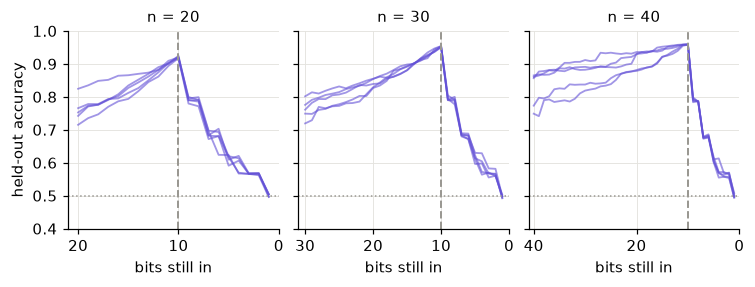

One line per fold; bits are removed from left to right. Dashed: bits kept. Dotted: 0.5.


In [5]:
et.table_elimination()
et.fig_elimination()

## Experiment 4: Polynomial Degree on the Kept Bits

*Future-work question:* what degree does a polynomial need? The same model class as Experiment 1, logistic regression (L2) on all monomials up to degree d, now on the bits kept inside each training fold. On at most 14 bits every degree up to 10 fits in memory.

Polynomial LR on the kept bits: CV accuracy by degree (mean ± sd over folds)
                  n = 20         n = 30         n = 40
---------  -------------  -------------  -------------
degree 1   0.500 ± 0.010  0.494 ± 0.016  0.507 ± 0.012
degree 2   0.555 ± 0.008  0.559 ± 0.016  0.572 ± 0.013
degree 3   0.579 ± 0.010  0.588 ± 0.010  0.591 ± 0.012
degree 4   0.680 ± 0.015  0.682 ± 0.016  0.667 ± 0.009
degree 5   0.793 ± 0.005  0.788 ± 0.008  0.780 ± 0.005
degree 6   0.957 ± 0.007  0.961 ± 0.003  0.960 ± 0.002
degree 7   0.957 ± 0.006  0.962 ± 0.002  0.960 ± 0.002
degree 8   0.957 ± 0.006  0.962 ± 0.002  0.960 ± 0.002
degree 9   0.958 ± 0.007  0.962 ± 0.002  0.960 ± 0.002
degree 10  0.958 ± 0.006  0.962 ± 0.002  0.960 ± 0.002


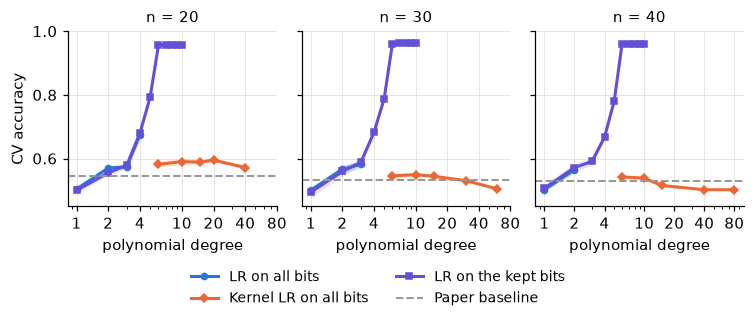

Mean over the folds (shaded: one sd), best setting at each degree.


In [6]:
for n in NS:
    for d in G["SEL_DEGS"]:
        for C in G["C_L2"]:
            cv_config(n, "LR", "lr_l2", "sel", f"deg{d}", dict(deg=d, C=C))
et.table_degree_sel()
et.fig_degree()

## Experiment 5: Amount of Training Data

*Claim:* quadrupling the training data does not help. *Future-work question:* how many examples are needed? The best model of each kind is trained on nested random subsets of the training folds and scored on the held-out fold (first three folds). For LR, `C` is scaled by (full rows / rows used) to keep the penalty per row fixed.

LC n=20 deg9                                                     0.489 ± 0.018  (197.9s)
LC n=20 deg9                                                     0.530 ± 0.045  (216.2s)
LC n=20 deg9                                                     0.632 ± 0.046  (233.6s)
LC n=20 deg9                                                     0.830 ± 0.068  (269.4s)
LC n=20 deg9                                                     0.944 ± 0.013  (270.6s)
LC n=20 deg4                                                     0.658 ± 0.002  (5.5s)
LC n=20 4x512                                                    0.487 ± 0.005  (5.4s)
LC n=20 4x512                                                    0.517 ± 0.020  (10.7s)
LC n=20 4x512                                                    0.526 ± 0.003  (21.0s)
LC n=20 4x512                                                    0.549 ± 0.007  (36.8s)
LC n=20 4x512                                                    0.606 ± 0.018  (98.0s)
LC n=30 deg7                 

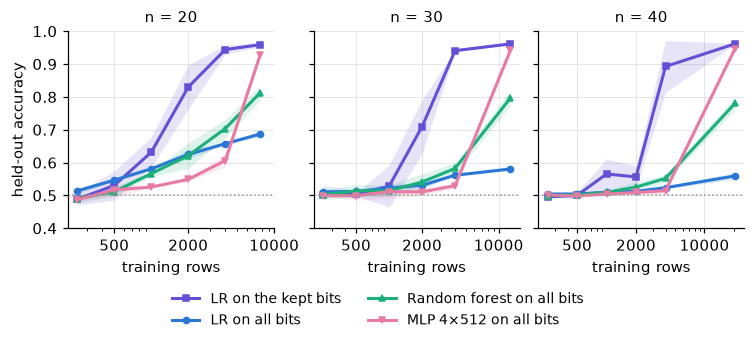

Mean over the first folds (shaded: one sd), each model at its CV-best setting. Dotted: 0.5


In [7]:
et.fig_learning_curves(et.run_learning_curves())

## Final Pipeline and Hidden-Set Predictions

The final pipeline for each n is the candidate with the highest CV mean, the paper baseline excluded. It is refitted on all dev rows, using the bits kept in a majority of folds, and scored on the locked 20%. Two controls on the first three folds should both give about 0.5: shuffled training labels (otherwise something leaks), and the same model on as many eliminated bits (otherwise the kept bits are not what carries the label). `check_caps` lists any fit that stopped at its iteration limit instead of converging.

For the hidden set the pipeline is refitted on all labelled rows. The hidden labels are unknown, so the predictions are checked against the best model of another kind (the MLP on all bits): if the two err on shares e₁ and e₂ of the rows, they can disagree on at most e₁ + e₂, so a lower agreement (with 2 points of slack) stops the notebook. The code then writes `hiddenlabels/y_predicted_{20,30,40}.npy` and runs the `check_submission.py`. `y_predicted_40_adapt.npy` comes from the LoRA notebook.

In [ ]:
FINAL = et.choose_final()
et.run_controls(FINAL)
et.table_final(FINAL)
et.check_caps()
print()
et.predict_hidden(FINAL)

n = 20: LR, L2, degree 9 on the kept bits (degree 9, C 0.001)
n = 30: LR, L2, degree 7 on the kept bits (degree 7, C 0.1)
n = 40: LR, L2, degree 7 on the kept bits (degree 7, C 0.1)
FINAL n=30 deg7                                                  0.959 ± 0.000  (402.2s)


## Summary

One row per approach, each at its best setting.

In [ ]:
et.fig_summary_table(FINAL)
et.table_summary(FINAL)

## Energy and Emissions

Measured with CodeCarbon while each result was computed: CPU energy from the processor's own energy counters (RAPL, read through the Windows Energy Meter Interface on Windows 11 or `/sys/class/powercap` on Linux), and GPU energy through NVML if an NVIDIA driver is present. The counters cover the whole machine's CPU, so other programs should be closed during the run. If CodeCarbon cannot read the counters, no figure is reported. Emissions use CodeCarbon's annual average carbon intensity of the UK grid.

In [ ]:
et.carbon_report()